# RQ8 — How much does the downstream learning algorithm matter?

## Scientific question

**After task definition, redundancy control, homology separation, and protein representation are fixed, how strongly does downstream classifier choice affect predictive performance and robustness?**

The primary matched unit is:

\[
\text{task}\times R\times S\times\text{representation}
\]

Within each such cell, compare the five frozen supervised learners:

- Logistic Regression (`LR`)
- Random Forest (`RF`)
- k-Nearest Neighbors (`KNN`)
- XGBoost (`XGB`)
- Multilayer Perceptron (`MLP`)

This isolates **algorithm choice** from the much larger changes caused by biological task definition and representation.

### Main questions

1. Is there a universally best downstream learner?
2. How large are paired algorithm effects?
3. Which algorithms win most often?
4. Does the preferred learner depend on protein representation?
5. Does stronger representation reduce the importance of classifier choice?
6. Which algorithms retain the best worst-case performance across the `R×S` landscape?
7. Which algorithms are most/least sensitive to redundancy reduction and homology separation?
8. Does algorithm ranking remain stable as the evaluation regime becomes stricter?
9. Is representation choice a larger source of predictive variation than classifier choice?
10. Are conclusions preserved with AP skill and multiclass macro-F1?

Runtime and memory are intentionally deferred to the dedicated compute RQ.

## Interpretation contract

- Algorithm comparisons are **paired** only when task, R, S, representation, and evaluated outer-test set are identical.
- MCC is the primary supervised metric.
- AP skill is used for binary ranking sensitivity.
- Macro-F1 is used as the main secondary multiclass check.
- “Best algorithm” frequencies are descriptive summaries of held-out test performance, **not a model-selection procedure**.
- A retrospective test-set winner must never be presented as the algorithm that would have been chosen prospectively.
- VAL remains a low-support stress-test regime and should not dominate pooled conclusions.

In [1]:
from pathlib import Path
from itertools import combinations
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 350)
pd.set_option("display.width", 240)
pd.set_option("display.max_rows", 350)

R_LEVELS = [90, 70, 50, 30]
S_LEVELS = [90, 70, 50, 30]

ALGORITHM_ORDER_PREFERRED = ["LR", "RF", "KNN", "XGB", "MLP"]

REP_ORDER_PREFERRED = [
    "roxy_48",
    "onehot_1024",
    "esm2_t6_8m",
    "esm2_t30_150m",
]

REP_LABEL = {
    "roxy_48": "Roxy",
    "onehot_1024": "One-hot",
    "esm2_t6_8m": "ESM2-T6",
    "esm2_t30_150m": "ESM2-T30",
}

BINARY_TASKS = [
    "global_easy",
    "global_hard",
    "global_mixed",
    "subtype_endolysin",
    "subtype_depolymerase",
    "subtype_val",
]

PAIR_TOL = 0.01

def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)

    for candidate in [start, *start.parents]:
        if (
            (candidate / "results/analysis_supervised/stage12a").is_dir()
            and (candidate / "results/analysis_supervised/stage12b").is_dir()
        ):
            return candidate

    raise FileNotFoundError(
        "Could not locate project root containing Stage12A and Stage12B."
    )

ROOT = find_project_root()
STAGE12A = ROOT / "results/analysis_supervised/stage12a"
STAGE12B = ROOT / "results/analysis_supervised/stage12b"
CACHE_DIR = ROOT / "results/analysis_supervised/notebook_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)

ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass


In [2]:
master = pd.read_csv(
    STAGE12A / "supervised_master_results.tsv",
    sep="\t",
    low_memory=False,
)

ALGORITHMS = [
    a for a in ALGORITHM_ORDER_PREFERRED
    if a in master["algorithm"].unique()
]

ALGORITHMS += [
    a for a in sorted(master["algorithm"].unique())
    if a not in ALGORITHMS
]

REPS = [
    r for r in REP_ORDER_PREFERRED
    if r in master["representation"].unique()
]

REPS += [
    r for r in sorted(master["representation"].unique())
    if r not in REPS
]

print("Experiment families:", len(master))
print("Algorithms:", ALGORITHMS)
print("Representations:", REPS)
print("Tasks:", sorted(master["task"].unique()))

coverage = (
    master.groupby(["task", "R", "S", "representation"])
    ["algorithm"]
    .nunique()
    .rename("n_algorithms")
    .reset_index()
)

display(
    coverage["n_algorithms"]
    .value_counts()
    .sort_index()
    .to_frame("n_matched_cells")
)

assert coverage["n_algorithms"].eq(len(ALGORITHMS)).all(), (
    "Incomplete algorithm coverage in one or more matched cells."
)

N_MATCHED = len(coverage)

print("Matched task×R×S×representation cells:", N_MATCHED)
print(
    "Expected algorithm-pair contrasts per metric:",
    N_MATCHED * len(list(combinations(ALGORITHMS, 2))),
)

Experiment families: 2240
Algorithms: ['LR', 'RF', 'KNN', 'XGB', 'MLP']
Representations: ['roxy_48', 'onehot_1024', 'esm2_t6_8m', 'esm2_t30_150m']
Tasks: ['global_easy', 'global_hard', 'global_mixed', 'multiclass_clean', 'subtype_depolymerase', 'subtype_endolysin', 'subtype_val']


,n_matched_cells
n_algorithms,
5,448


Matched task×R×S×representation cells: 448
Expected algorithm-pair contrasts per metric: 4480


# 1. Prevalence-normalized AP skill

In [3]:
def detect_prevalence(df):
    for c in [
        "test_prevalence",
        "prevalence",
        "positive_prevalence",
        "class_prevalence",
    ]:
        if c in df.columns:
            return pd.to_numeric(df[c], errors="coerce"), c

    if {"n_positive", "n_test"} <= set(df.columns):
        return (
            pd.to_numeric(df["n_positive"], errors="coerce")
            / pd.to_numeric(df["n_test"], errors="coerce")
        ), "derived_from_n_positive_n_test"

    if {"tp", "fn", "tn", "fp"} <= set(df.columns):
        pos = (
            pd.to_numeric(df["tp"], errors="coerce")
            + pd.to_numeric(df["fn"], errors="coerce")
        )
        n = (
            pos
            + pd.to_numeric(df["tn"], errors="coerce")
            + pd.to_numeric(df["fp"], errors="coerce")
        )
        return pos / n, "derived_from_confusion_counts"

    return pd.Series(np.nan, index=df.index), None

prev, prev_source = detect_prevalence(master)
master["prevalence_for_ap"] = prev

if "ap" in master.columns:
    denom = 1.0 - master["prevalence_for_ap"]
    master["ap_skill"] = np.where(
        denom > 0,
        (master["ap"] - master["prevalence_for_ap"]) / denom,
        np.nan,
    )

print("Prevalence source:", prev_source)

Prevalence source: prevalence


# 2. Overall performance by algorithm

In [4]:
overall_alg = (
    master.groupby("algorithm")
    .agg(
        n=("mcc", "size"),
        mcc_mean=("mcc", "mean"),
        mcc_median=("mcc", "median"),
        mcc_q25=("mcc", lambda x: x.quantile(0.25)),
        mcc_q75=("mcc", lambda x: x.quantile(0.75)),
        mcc_min=("mcc", "min"),
        mcc_max=("mcc", "max"),
    )
    .reindex(ALGORITHMS)
)

display(overall_alg)

,n,mcc_mean,mcc_median,mcc_q25,mcc_q75,mcc_min,mcc_max
algorithm,,,,,,,
LR,448,0.659305,0.717204,0.489846,0.846582,0.0,0.954778
RF,448,0.627663,0.742485,0.470591,0.857167,0.0,0.962872
KNN,448,0.736548,0.784003,0.643293,0.890861,0.0,0.964477
XGB,448,0.727975,0.796415,0.611935,0.886045,0.0,0.959317
MLP,448,0.741912,0.817299,0.658542,0.888416,0.0,0.963380


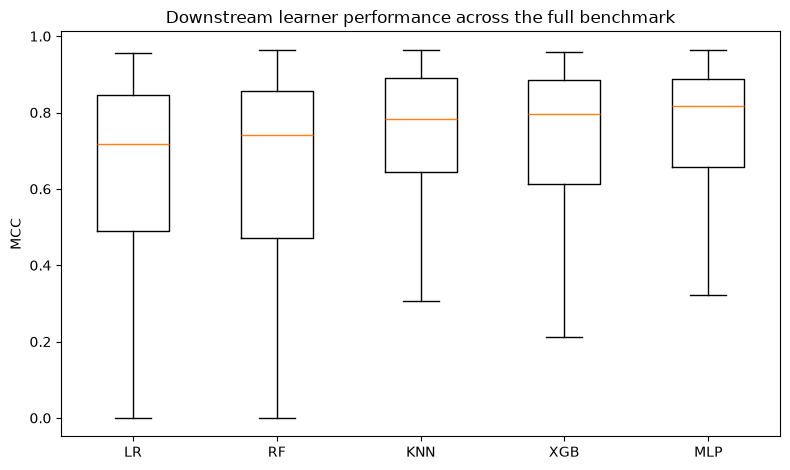

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.8))

data = [
    master.loc[
        master["algorithm"].eq(alg),
        "mcc",
    ].dropna().to_numpy()
    for alg in ALGORITHMS
]

ax.boxplot(
    data,
    tick_labels=ALGORITHMS,
    showfliers=False,
)
ax.set_ylabel("MCC")
ax.set_title("Downstream learner performance across the full benchmark")
plt.tight_layout()
plt.show()

Pooled distributions are descriptive only. The main evidence below uses matched comparisons inside identical `task × R × S × representation` cells.

# 3. Build all matched algorithm contrasts

In [6]:
def paired_algorithm_table(df, metric):
    rows = []

    group_cols = ["task", "R", "S", "representation"]

    for keys, grp in df.groupby(group_cols):
        task, r, s, rep = keys

        lookup = dict(
            zip(
                grp["algorithm"],
                pd.to_numeric(grp[metric], errors="coerce"),
            )
        )

        for alg_a, alg_b in combinations(ALGORITHMS, 2):
            if (
                alg_a not in lookup
                or alg_b not in lookup
                or pd.isna(lookup[alg_a])
                or pd.isna(lookup[alg_b])
            ):
                continue

            rows.append(
                {
                    "task": task,
                    "R": int(r),
                    "S": int(s),
                    "representation": rep,
                    "metric": metric,
                    "algorithm_A": alg_a,
                    "algorithm_B": alg_b,
                    "value_A": float(lookup[alg_a]),
                    "value_B": float(lookup[alg_b]),
                    "delta_B_minus_A": (
                        float(lookup[alg_b])
                        - float(lookup[alg_a])
                    ),
                }
            )

    return pd.DataFrame(rows)

alg_mcc = paired_algorithm_table(master, "mcc")

expected_pairs = N_MATCHED * len(list(combinations(ALGORITHMS, 2)))

print("Matched MCC algorithm contrasts:", len(alg_mcc))
print("Expected:", expected_pairs)

assert len(alg_mcc) == expected_pairs

display(alg_mcc.head())

Matched MCC algorithm contrasts: 4480
Expected: 4480


,task,R,S,representation,metric,algorithm_A,algorithm_B,value_A,value_B,delta_B_minus_A
0,global_easy,30,30,esm2_t30_150m,mcc,LR,RF,0.840543,0.831723,-0.008820
1,global_easy,30,30,esm2_t30_150m,mcc,LR,KNN,0.840543,0.887662,0.047119
2,global_easy,30,30,esm2_t30_150m,mcc,LR,XGB,0.840543,0.879389,0.038846
3,global_easy,30,30,esm2_t30_150m,mcc,LR,MLP,0.840543,0.877293,0.036749
4,global_easy,30,30,esm2_t30_150m,mcc,RF,KNN,0.831723,0.887662,0.055939


# 4. Pairwise ΔMCC and win/tie/loss

In [7]:
pair_rows = []

for (a, b), grp in alg_mcc.groupby(
    ["algorithm_A", "algorithm_B"]
):
    d = grp["delta_B_minus_A"].dropna()

    pair_rows.append(
        {
            "algorithm_A": a,
            "algorithm_B": b,
            "comparison": f"{b} − {a}",
            "n": len(d),
            "mean_delta": d.mean(),
            "median_delta": d.median(),
            "q25": d.quantile(0.25),
            "q75": d.quantile(0.75),
            "fraction_B_better": (d > PAIR_TOL).mean(),
            "fraction_tie": (d.abs() <= PAIR_TOL).mean(),
            "fraction_A_better": (d < -PAIR_TOL).mean(),
            "fraction_delta_positive": (d > 0).mean(),
        }
    )

pair_summary = (
    pd.DataFrame(pair_rows)
    .sort_values("median_delta", ascending=False)
)

display(pair_summary)

,algorithm_A,algorithm_B,comparison,n,mean_delta,median_delta,q25,q75,fraction_B_better,fraction_tie,fraction_A_better,fraction_delta_positive
2,LR,KNN,KNN − LR,448,0.077242,0.064227,0.004703,0.138276,0.727679,0.118304,0.154018,0.772321
7,RF,MLP,MLP − RF,448,0.114248,0.052590,0.020221,0.121762,0.810268,0.118304,0.071429,0.861607
8,RF,XGB,XGB − RF,448,0.100311,0.047913,0.018633,0.108615,0.799107,0.151786,0.049107,0.881696
3,LR,MLP,MLP − LR,448,0.082607,0.047717,0.006089,0.139239,0.727679,0.165179,0.107143,0.787946
6,RF,KNN,KNN − RF,448,0.108884,0.043845,0.007412,0.098597,0.736607,0.160714,0.102679,0.816964
5,LR,XGB,XGB − LR,448,0.068670,0.039360,-0.003744,0.130465,0.640625,0.149554,0.209821,0.696429
0,KNN,MLP,MLP − KNN,448,0.005364,0.006521,-0.007278,0.027305,0.453125,0.325893,0.220982,0.602679
4,LR,RF,RF − LR,448,-0.031642,0.005962,-0.078889,0.063375,0.459821,0.174107,0.366071,0.551339
9,XGB,MLP,MLP − XGB,448,0.013937,0.005960,-0.006480,0.027934,0.417411,0.372768,0.209821,0.611607
1,KNN,XGB,XGB − KNN,448,-0.008573,0.000257,-0.021008,0.022222,0.343750,0.325893,0.330357,0.502232


# 5. Pairwise median-delta matrix

In [8]:
delta_matrix = pd.DataFrame(
    0.0,
    index=ALGORITHMS,
    columns=ALGORITHMS,
)

for _, row in pair_summary.iterrows():
    a = row["algorithm_A"]
    b = row["algorithm_B"]
    delta = row["median_delta"]

    delta_matrix.loc[b, a] = delta
    delta_matrix.loc[a, b] = -delta

display(delta_matrix)

,LR,RF,KNN,XGB,MLP
LR,0.000000,-0.005962,-0.064227,-0.039360,-0.047717
RF,0.005962,0.000000,-0.043845,-0.047913,-0.052590
KNN,0.064227,0.043845,0.000000,-0.000257,-0.006521
XGB,0.039360,0.047913,0.000257,0.000000,-0.005960
MLP,0.047717,0.052590,0.006521,0.005960,0.000000


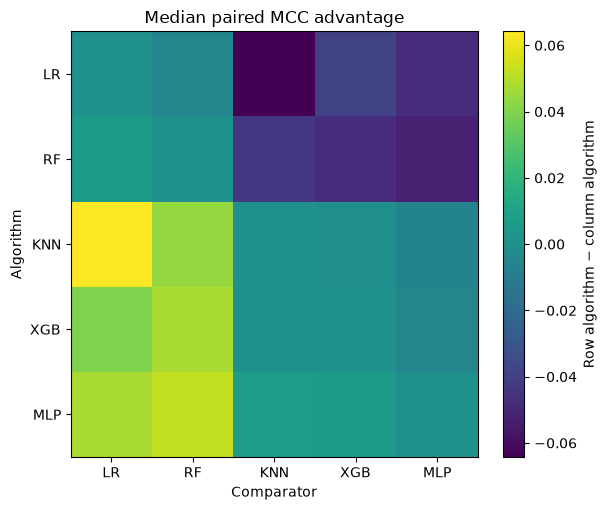

In [9]:
fig, ax = plt.subplots(figsize=(6.2, 5.2))
im = ax.imshow(delta_matrix.to_numpy(), aspect="auto")

ax.set_xticks(range(len(ALGORITHMS)), ALGORITHMS)
ax.set_yticks(range(len(ALGORITHMS)), ALGORITHMS)
ax.set_xlabel("Comparator")
ax.set_ylabel("Algorithm")
ax.set_title("Median paired MCC advantage")
plt.colorbar(im, ax=ax, label="Row algorithm − column algorithm")
plt.tight_layout()
plt.show()

# 6. Algorithm ranks within matched cells

In [10]:
rank_rows = []

for keys, grp in master.groupby(
    ["task", "R", "S", "representation"]
):
    task, r, s, rep = keys

    g = grp[
        ["algorithm", "mcc"]
    ].dropna().copy()

    if len(g) != len(ALGORITHMS):
        continue

    g["rank"] = (
        g["mcc"]
        .rank(method="average", ascending=False)
    )

    max_mcc = g["mcc"].max()

    for rec in g.to_dict("records"):
        rank_rows.append(
            {
                "task": task,
                "R": int(r),
                "S": int(s),
                "representation": rep,
                "algorithm": rec["algorithm"],
                "mcc": rec["mcc"],
                "rank": rec["rank"],
                "best_mcc": max_mcc,
                "gap_to_best": max_mcc - rec["mcc"],
            }
        )

alg_ranks = pd.DataFrame(rank_rows)

rank_summary = (
    alg_ranks.groupby("algorithm")
    .agg(
        mean_rank=("rank", "mean"),
        median_rank=("rank", "median"),
        first_place_fraction=(
            "rank",
            lambda x: (x == 1).mean(),
        ),
        top2_fraction=(
            "rank",
            lambda x: (x <= 2).mean(),
        ),
        median_gap_to_best=("gap_to_best", "median"),
        mean_gap_to_best=("gap_to_best", "mean"),
    )
    .reindex(ALGORITHMS)
)

display(rank_summary)

,mean_rank,median_rank,first_place_fraction,top2_fraction,median_gap_to_best,mean_gap_to_best
algorithm,,,,,,
LR,3.859375,5.0,0.118304,0.196429,0.074941,0.107664
RF,4.030134,4.0,0.049107,0.095982,0.063918,0.139305
KNN,2.523438,3.0,0.272321,0.457589,0.013871,0.030421
XGB,2.515625,2.5,0.209821,0.497768,0.012138,0.038994
MLP,2.071429,2.0,0.319196,0.691964,0.007976,0.025057


Because ties can occur, first-place fractions may sum to more than 1 when multiple algorithms share the same MCC.

# 7. Algorithm behavior by biological task

In [11]:
task_alg = (
    master.groupby(["task", "algorithm"])
    .agg(
        mcc_mean=("mcc", "mean"),
        mcc_median=("mcc", "median"),
        mcc_min=("mcc", "min"),
    )
    .reset_index()
)

display(
    task_alg.pivot(
        index="task",
        columns="algorithm",
        values="mcc_median",
    ).reindex(columns=ALGORITHMS)
)

algorithm,LR,RF,KNN,XGB,MLP
task,,,,,
global_easy,0.640170,0.701167,0.753685,0.766833,0.764263
global_hard,0.884945,0.899841,0.887874,0.902518,0.886794
global_mixed,0.614878,0.704597,0.752693,0.776383,0.773149
multiclass_clean,0.744600,0.794522,0.826088,0.829453,0.824460
subtype_depolymerase,0.769980,0.853584,0.859427,0.853766,0.855852
subtype_endolysin,0.578440,0.648648,0.712253,0.731928,0.738886
subtype_val,0.406593,0.337318,0.619642,0.598564,0.632933


In [12]:
task_rank = (
    alg_ranks.groupby(["task", "algorithm"])
    .agg(
        mean_rank=("rank", "mean"),
        first_place_fraction=(
            "rank",
            lambda x: (x == 1).mean(),
        ),
        median_gap_to_best=("gap_to_best", "median"),
    )
    .reset_index()
)

display(
    task_rank.pivot(
        index="task",
        columns="algorithm",
        values="mean_rank",
    ).reindex(columns=ALGORITHMS)
)

algorithm,LR,RF,KNN,XGB,MLP
task,,,,,
global_easy,4.171875,4.421875,2.187500,2.406250,1.812500
global_hard,2.835938,3.125000,3.726562,2.382812,2.929688
global_mixed,4.406250,4.234375,2.187500,2.343750,1.828125
multiclass_clean,3.734375,4.046875,2.421875,2.812500,1.984375
subtype_depolymerase,3.843750,3.906250,2.492188,2.773438,1.984375
subtype_endolysin,4.468750,4.265625,2.218750,2.250000,1.796875
subtype_val,3.554688,4.210938,2.429688,2.640625,2.164062


# 8. Does the preferred learner depend on protein representation?

In [13]:
rep_alg = (
    master.groupby(["representation", "algorithm"])
    .agg(
        mcc_mean=("mcc", "mean"),
        mcc_median=("mcc", "median"),
        mcc_min=("mcc", "min"),
    )
    .reset_index()
)

display(
    rep_alg.pivot(
        index="representation",
        columns="algorithm",
        values="mcc_median",
    )
    .reindex(index=REPS, columns=ALGORITHMS)
)

algorithm,LR,RF,KNN,XGB,MLP
representation,,,,,
roxy_48,0.490366,0.679386,0.713270,0.735905,0.715244
onehot_1024,0.498313,0.158292,0.622187,0.493537,0.545145
esm2_t6_8m,0.756676,0.797675,0.846732,0.851506,0.859685
esm2_t30_150m,0.881722,0.879959,0.914002,0.911199,0.917424


In [14]:
rep_rank = (
    alg_ranks.groupby(["representation", "algorithm"])
    .agg(
        mean_rank=("rank", "mean"),
        median_rank=("rank", "median"),
        first_place_fraction=(
            "rank",
            lambda x: (x == 1).mean(),
        ),
        median_gap_to_best=("gap_to_best", "median"),
    )
    .reset_index()
)

display(
    rep_rank.pivot(
        index="representation",
        columns="algorithm",
        values="mean_rank",
    )
    .reindex(index=REPS, columns=ALGORITHMS)
)

algorithm,LR,RF,KNN,XGB,MLP
representation,,,,,
roxy_48,4.848214,3.267857,3.183036,1.486607,2.214286
onehot_1024,2.299107,4.647321,2.290179,3.575893,2.187500
esm2_t6_8m,4.410714,4.008929,2.459821,2.330357,1.790179
esm2_t30_150m,3.879464,4.196429,2.160714,2.669643,2.093750


This is the core representation × learner interaction question:

> Does classifier choice remain important after the representation itself becomes strong?

A strong representation may make simple and complex downstream learners more similar even if their absolute performances remain high.

# 9. How much does algorithm choice matter within each representation?

In [15]:
cell_spread_rows = []

for keys, grp in master.groupby(
    ["task", "R", "S", "representation"]
):
    task, r, s, rep = keys

    vals = grp["mcc"].dropna()

    if len(vals) != len(ALGORITHMS):
        continue

    cell_spread_rows.append(
        {
            "task": task,
            "R": int(r),
            "S": int(s),
            "representation": rep,
            "algorithm_range": vals.max() - vals.min(),
            "algorithm_std": vals.std(ddof=0),
            "algorithm_iqr": vals.quantile(0.75) - vals.quantile(0.25),
        }
    )

algorithm_spread = pd.DataFrame(cell_spread_rows)

spread_by_rep = (
    algorithm_spread.groupby("representation")
    .agg(
        median_range=("algorithm_range", "median"),
        mean_range=("algorithm_range", "mean"),
        median_std=("algorithm_std", "median"),
        median_iqr=("algorithm_iqr", "median"),
    )
    .reindex(REPS)
)

display(spread_by_rep)

,median_range,mean_range,median_std,median_iqr
representation,,,,
roxy_48,0.235909,0.232045,0.084103,0.037938
onehot_1024,0.306152,0.312182,0.114293,0.053957
esm2_t6_8m,0.114780,0.138826,0.044715,0.057434
esm2_t30_150m,0.051091,0.084625,0.019378,0.028438


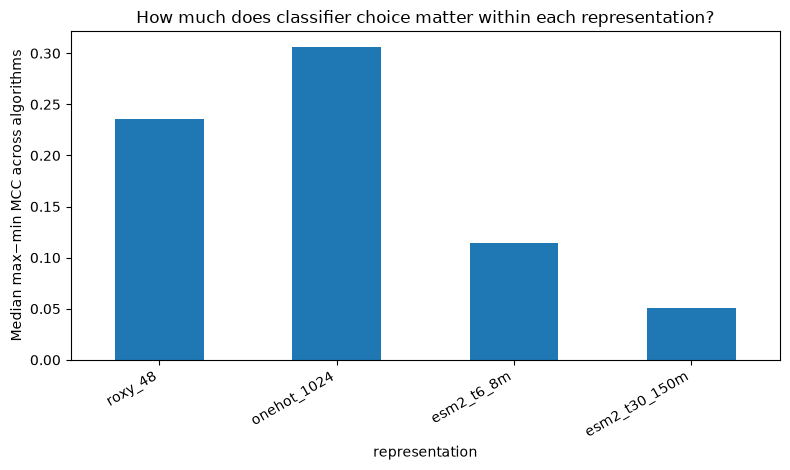

In [16]:
spread_by_rep["median_range"].plot(
    kind="bar",
    figsize=(8, 4.8),
)
plt.ylabel("Median max−min MCC across algorithms")
plt.title("How much does classifier choice matter within each representation?")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# 10. Does algorithm sensitivity change with R and S?

In [17]:
spread_by_R = (
    algorithm_spread.groupby("R")[
        "algorithm_range"
    ]
    .agg(["mean", "median", "std"])
    .reindex(R_LEVELS)
)

spread_by_S = (
    algorithm_spread.groupby("S")[
        "algorithm_range"
    ]
    .agg(["mean", "median", "std"])
    .reindex(S_LEVELS)
)

print("Algorithm spread by R")
display(spread_by_R)

print("Algorithm spread by S")
display(spread_by_S)

Algorithm spread by R


,mean,median,std
R,,,
90,0.198507,0.131992,0.176544
70,0.206453,0.134139,0.183889
50,0.203459,0.144884,0.192865
30,0.159259,0.120762,0.131671


Algorithm spread by S


,mean,median,std
S,,,
90,0.189195,0.129692,0.173088
70,0.196664,0.133617,0.175403
50,0.199533,0.133795,0.174234
30,0.182286,0.125452,0.172394


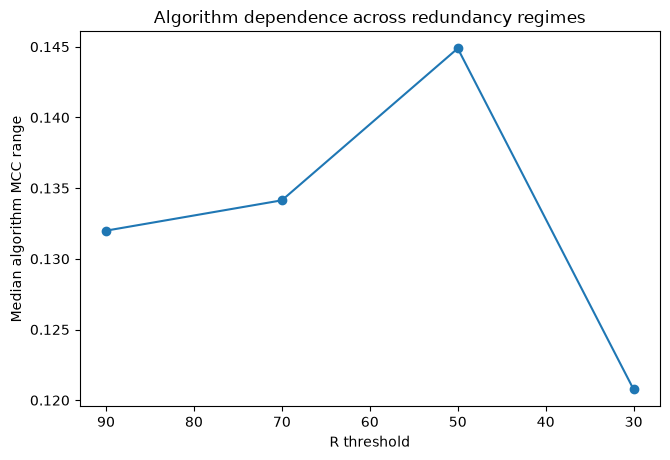

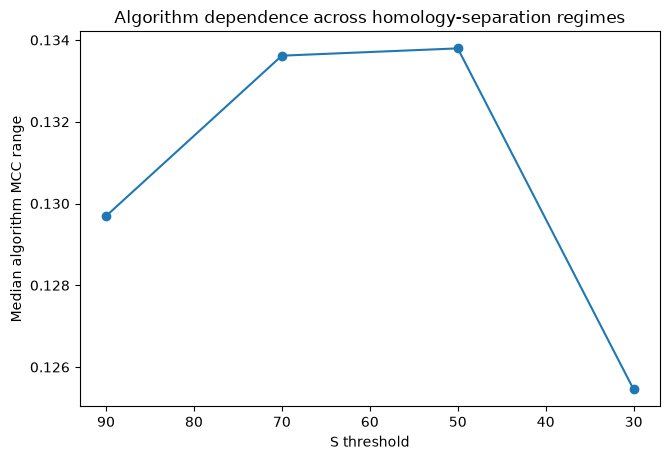

In [18]:
fig, ax = plt.subplots(figsize=(6.8, 4.7))
ax.plot(
    R_LEVELS,
    spread_by_R["median"],
    marker="o",
)
ax.set_xlabel("R threshold")
ax.set_ylabel("Median algorithm MCC range")
ax.set_title("Algorithm dependence across redundancy regimes")
ax.invert_xaxis()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6.8, 4.7))
ax.plot(
    S_LEVELS,
    spread_by_S["median"],
    marker="o",
)
ax.set_xlabel("S threshold")
ax.set_ylabel("Median algorithm MCC range")
ax.set_title("Algorithm dependence across homology-separation regimes")
ax.invert_xaxis()
plt.tight_layout()
plt.show()

# 11. Simple LR versus nonlinear learners

In [19]:
lr_rows = []

for comparator in [a for a in ALGORITHMS if a != "LR"]:
    rows = alg_mcc[
        (
            alg_mcc["algorithm_A"].eq("LR")
            & alg_mcc["algorithm_B"].eq(comparator)
        )
        |
        (
            alg_mcc["algorithm_B"].eq("LR")
            & alg_mcc["algorithm_A"].eq(comparator)
        )
    ].copy()

    if len(rows) == 0:
        continue

    rows["delta_comparator_minus_LR"] = np.where(
        rows["algorithm_A"].eq("LR"),
        rows["delta_B_minus_A"],
        -rows["delta_B_minus_A"],
    )

    rows["comparator"] = comparator
    lr_rows.append(rows)

lr_comparisons = (
    pd.concat(lr_rows, ignore_index=True)
    if lr_rows
    else pd.DataFrame()
)

display(
    lr_comparisons.groupby("comparator")[
        "delta_comparator_minus_LR"
    ]
    .agg(
        n="size",
        mean="mean",
        median="median",
        fraction_positive=lambda x: (x > 0).mean(),
        fraction_gt_001=lambda x: (x > PAIR_TOL).mean(),
        fraction_LR_better_gt_001=lambda x: (x < -PAIR_TOL).mean(),
    )
)

,n,mean,median,fraction_positive,fraction_gt_001,fraction_LR_better_gt_001
comparator,,,,,,
KNN,448,0.077242,0.064227,0.772321,0.727679,0.154018
MLP,448,0.082607,0.047717,0.787946,0.727679,0.107143
RF,448,-0.031642,0.005962,0.551339,0.459821,0.366071
XGB,448,0.068670,0.039360,0.696429,0.640625,0.209821


# 12. LR competitiveness depends on representation

In [20]:
if len(lr_comparisons):
    display(
        lr_comparisons.groupby(
            ["representation", "comparator"]
        )["delta_comparator_minus_LR"]
        .agg(
            mean="mean",
            median="median",
            fraction_positive=lambda x: (x > 0).mean(),
        )
        .reset_index()
    )

,representation,comparator,mean,median,fraction_positive
0,esm2_t30_150m,KNN,0.021141,0.028763,0.785714
1,esm2_t30_150m,MLP,0.031691,0.034526,0.821429
2,esm2_t30_150m,RF,-0.039432,0.000790,0.508929
3,esm2_t30_150m,XGB,0.013454,0.022620,0.758929
4,esm2_t6_8m,KNN,0.080113,0.095945,0.883929
5,esm2_t6_8m,MLP,0.095187,0.106352,0.901786
6,esm2_t6_8m,RF,-0.003024,0.028821,0.714286
7,esm2_t6_8m,XGB,0.081583,0.093953,0.910714
8,onehot_1024,KNN,0.026989,0.000000,0.491071
9,onehot_1024,MLP,-0.003047,0.000000,0.473214


If nonlinear-vs-LR gains shrink on stronger PLM embeddings, the scientific interpretation is not that nonlinear models are “unnecessary” in general, but that **representation quality can absorb part of the burden otherwise placed on the downstream decision function**.

# 13. Strict-corner algorithm ranking: R30_S30

In [21]:
strict = master[
    master["R"].eq(30)
    & master["S"].eq(30)
].copy()

strict_alg = (
    strict.groupby("algorithm")
    .agg(
        n=("mcc", "size"),
        mcc_mean=("mcc", "mean"),
        mcc_median=("mcc", "median"),
        mcc_q25=("mcc", lambda x: x.quantile(0.25)),
        mcc_min=("mcc", "min"),
    )
    .reindex(ALGORITHMS)
)

display(strict_alg)

,n,mcc_mean,mcc_median,mcc_q25,mcc_min
algorithm,,,,,
LR,28,0.643024,0.692668,0.471259,0.0
RF,28,0.604233,0.694752,0.483446,0.0
KNN,28,0.680271,0.752852,0.565133,0.0
XGB,28,0.689657,0.759450,0.578084,0.0
MLP,28,0.704443,0.785579,0.627077,0.0


# 14. Worst-case robustness across each full R×S surface

In [22]:
worst_rows = []

for keys, grp in master.groupby(
    ["task", "representation", "algorithm"]
):
    task, rep, alg = keys

    if len(grp) != 16:
        continue

    worst_rows.append(
        {
            "task": task,
            "representation": rep,
            "algorithm": alg,
            "worst_mcc": grp["mcc"].min(),
            "median_mcc": grp["mcc"].median(),
            "best_mcc": grp["mcc"].max(),
            "surface_range": grp["mcc"].max() - grp["mcc"].min(),
        }
    )

worst_case = pd.DataFrame(worst_rows)

worst_alg = (
    worst_case.groupby("algorithm")
    .agg(
        median_worst_mcc=("worst_mcc", "median"),
        mean_worst_mcc=("worst_mcc", "mean"),
        median_surface_mcc=("median_mcc", "median"),
        median_surface_range=("surface_range", "median"),
    )
    .reindex(ALGORITHMS)
)

display(worst_alg)

,median_worst_mcc,mean_worst_mcc,median_surface_mcc,median_surface_range
algorithm,,,,
LR,0.665371,0.590094,0.713508,0.120340
RF,0.677325,0.538769,0.739699,0.141476
KNN,0.700916,0.626087,0.791335,0.142134
XGB,0.718154,0.644001,0.809511,0.124411
MLP,0.751665,0.653695,0.831680,0.126295


# 15. Robustness to redundancy reduction

In [23]:
r_rows = []

for keys, grp in master.groupby(
    ["task", "representation", "algorithm", "S"]
):
    task, rep, alg, s = keys

    lookup = dict(zip(grp["R"].astype(int), grp["mcc"]))

    if 90 in lookup and 30 in lookup:
        r_rows.append(
            {
                "task": task,
                "representation": rep,
                "algorithm": alg,
                "S": int(s),
                "delta_R30_minus_R90": (
                    lookup[30] - lookup[90]
                ),
            }
        )

r_robustness = pd.DataFrame(r_rows)

display(
    r_robustness.groupby("algorithm")[
        "delta_R30_minus_R90"
    ]
    .agg(
        mean="mean",
        median="median",
        median_abs=lambda x: x.abs().median(),
        fraction_negative=lambda x: (x < 0).mean(),
    )
    .reindex(ALGORITHMS)
)

,mean,median,median_abs,fraction_negative
algorithm,,,,
LR,-0.044670,-0.051464,0.062644,0.767857
RF,-0.063485,-0.081927,0.091442,0.776786
KNN,-0.106397,-0.083245,0.088282,0.892857
XGB,-0.076797,-0.076951,0.078729,0.812500
MLP,-0.074506,-0.071688,0.076000,0.857143


# 16. Robustness to remote homology separation

In [24]:
s_rows = []

for keys, grp in master.groupby(
    ["task", "representation", "algorithm", "R"]
):
    task, rep, alg, r = keys

    lookup = dict(zip(grp["S"].astype(int), grp["mcc"]))

    if 90 in lookup and 30 in lookup:
        s_rows.append(
            {
                "task": task,
                "representation": rep,
                "algorithm": alg,
                "R": int(r),
                "delta_S30_minus_S90": (
                    lookup[30] - lookup[90]
                ),
            }
        )

s_robustness = pd.DataFrame(s_rows)

display(
    s_robustness.groupby("algorithm")[
        "delta_S30_minus_S90"
    ]
    .agg(
        mean="mean",
        median="median",
        median_abs=lambda x: x.abs().median(),
        fraction_negative=lambda x: (x < 0).mean(),
    )
    .reindex(ALGORITHMS)
)

,mean,median,median_abs,fraction_negative
algorithm,,,,
LR,-0.024145,-0.009153,0.017958,0.642857
RF,-0.045615,-0.018467,0.022205,0.732143
KNN,-0.057052,-0.023941,0.031840,0.723214
XGB,-0.035048,-0.017731,0.023451,0.714286
MLP,-0.031611,-0.016422,0.022279,0.732143


# 17. Which learner is most robust within each representation?

In [25]:
rep_r_rob = (
    r_robustness.groupby(
        ["representation", "algorithm"]
    )["delta_R30_minus_R90"]
    .agg(
        median="median",
        median_abs=lambda x: x.abs().median(),
    )
    .reset_index()
)

rep_s_rob = (
    s_robustness.groupby(
        ["representation", "algorithm"]
    )["delta_S30_minus_S90"]
    .agg(
        median="median",
        median_abs=lambda x: x.abs().median(),
    )
    .reset_index()
)

print("R robustness")
display(
    rep_r_rob.pivot(
        index="representation",
        columns="algorithm",
        values="median_abs",
    ).reindex(index=REPS, columns=ALGORITHMS)
)

print("S robustness")
display(
    rep_s_rob.pivot(
        index="representation",
        columns="algorithm",
        values="median_abs",
    ).reindex(index=REPS, columns=ALGORITHMS)
)

R robustness


algorithm,LR,RF,KNN,XGB,MLP
representation,,,,,
roxy_48,0.059675,0.100686,0.108065,0.104301,0.088470
onehot_1024,0.077120,0.092343,0.208234,0.090375,0.110544
esm2_t6_8m,0.062713,0.090352,0.084669,0.083838,0.083755
esm2_t30_150m,0.065272,0.082992,0.064316,0.064784,0.053691


S robustness


algorithm,LR,RF,KNN,XGB,MLP
representation,,,,,
roxy_48,0.018757,0.035722,0.044584,0.040797,0.037701
onehot_1024,0.036330,0.039642,0.067772,0.030445,0.033905
esm2_t6_8m,0.018789,0.015546,0.024688,0.022222,0.019060
esm2_t30_150m,0.014776,0.017767,0.014855,0.017731,0.010390


# 18. Stability of the algorithm winner across the 16 R×S conditions

For each `task × representation`, identify the retrospective best-MCC algorithm in each of the 16 cells.

Summaries:

- number of distinct winners;
- fraction of cells won by the modal algorithm;
- winner entropy.

A high modal fraction and low entropy indicate stable learner preference.  
A low modal fraction indicates that the apparent best learner depends strongly on the evaluation regime.

In [26]:
winner_rows = []

for keys, grp in master.groupby(
    ["task", "representation", "R", "S"]
):
    task, rep, r, s = keys

    max_mcc = grp["mcc"].max()

    winners = sorted(
        grp.loc[
            grp["mcc"].eq(max_mcc),
            "algorithm",
        ].astype(str).tolist()
    )

    # If exact ties occur, retain all tied winners as one composite state.
    winner_state = "|".join(winners)

    winner_rows.append(
        {
            "task": task,
            "representation": rep,
            "R": int(r),
            "S": int(s),
            "winner_state": winner_state,
            "n_tied_winners": len(winners),
        }
    )

winner_cells = pd.DataFrame(winner_rows)

winner_stability_rows = []

for keys, grp in winner_cells.groupby(
    ["task", "representation"]
):
    task, rep = keys

    freq = grp["winner_state"].value_counts(normalize=True)
    modal_fraction = freq.iloc[0]
    entropy = -float(
        np.sum(
            freq.to_numpy()
            * np.log2(freq.to_numpy())
        )
    )

    winner_stability_rows.append(
        {
            "task": task,
            "representation": rep,
            "n_cells": len(grp),
            "n_distinct_winner_states": grp[
                "winner_state"
            ].nunique(),
            "modal_winner_state": freq.index[0],
            "modal_fraction": modal_fraction,
            "winner_entropy_bits": entropy,
        }
    )

winner_stability = pd.DataFrame(
    winner_stability_rows
)

display(
    winner_stability.groupby("representation")
    .agg(
        median_distinct_winners=(
            "n_distinct_winner_states",
            "median",
        ),
        median_modal_fraction=(
            "modal_fraction",
            "median",
        ),
        median_entropy=(
            "winner_entropy_bits",
            "median",
        ),
    )
    .reindex(REPS)
)

,median_distinct_winners,median_modal_fraction,median_entropy
representation,,,
roxy_48,3.0,0.6250,1.198192
onehot_1024,3.0,0.6875,1.199460
esm2_t6_8m,3.0,0.6875,1.061278
esm2_t30_150m,4.0,0.5000,1.748999


# 19. Does the winner change between permissive and strict corners?

In [27]:
corner_winners = winner_cells[
    (
        winner_cells["R"].eq(90)
        & winner_cells["S"].eq(90)
    )
    |
    (
        winner_cells["R"].eq(30)
        & winner_cells["S"].eq(30)
    )
].copy()

corner_wide = corner_winners.pivot_table(
    index=["task", "representation"],
    columns=["R", "S"],
    values="winner_state",
    aggfunc="first",
)

if (90, 90) in corner_wide.columns and (30, 30) in corner_wide.columns:
    corner_change = pd.DataFrame(
        {
            "winner_R90_S90": corner_wide[(90, 90)],
            "winner_R30_S30": corner_wide[(30, 30)],
        }
    ).reset_index()

    corner_change["winner_changed"] = (
        corner_change["winner_R90_S90"]
        != corner_change["winner_R30_S30"]
    )

    print(
        "Fraction task×representation surfaces whose retrospective winner changes:",
        corner_change["winner_changed"].mean(),
    )

    display(
        corner_change.groupby("representation")[
            "winner_changed"
        ].mean().reindex(REPS)
    )
else:
    corner_change = pd.DataFrame()

Fraction task×representation surfaces whose retrospective winner changes: 0.6428571428571429


representation
roxy_48          0.857143
onehot_1024      0.571429
esm2_t6_8m       0.857143
esm2_t30_150m    0.285714
Name: winner_changed, dtype: float64

# 20. Representation choice versus algorithm choice

RQ6 established large representation effects. RQ8 can now compare the **within-cell predictive spread** generated by changing representation versus changing algorithm.

For each `task × R × S` condition:

### Algorithm spread
For each representation, calculate:

\[
\max_{\text{alg}} MCC-\min_{\text{alg}} MCC
\]

then take the median across representations.

### Representation spread
For each algorithm, calculate:

\[
\max_{\text{rep}} MCC-\min_{\text{rep}} MCC
\]

then take the median across algorithms.

This is a descriptive comparison of factor importance, not an ANOVA.

In [28]:
factor_spread_rows = []

for keys, grp in master.groupby(
    ["task", "R", "S"]
):
    task, r, s = keys

    alg_spreads = (
        grp.groupby("representation")["mcc"]
        .agg(lambda x: x.max() - x.min())
    )

    rep_spreads = (
        grp.groupby("algorithm")["mcc"]
        .agg(lambda x: x.max() - x.min())
    )

    factor_spread_rows.append(
        {
            "task": task,
            "R": int(r),
            "S": int(s),
            "median_algorithm_spread": alg_spreads.median(),
            "median_representation_spread": rep_spreads.median(),
            "representation_minus_algorithm_spread": (
                rep_spreads.median() - alg_spreads.median()
            ),
            "representation_to_algorithm_spread_ratio": (
                rep_spreads.median() / alg_spreads.median()
                if alg_spreads.median() > 0
                else np.nan
            ),
        }
    )

factor_spread = pd.DataFrame(factor_spread_rows)

display(
    factor_spread[
        [
            "median_algorithm_spread",
            "median_representation_spread",
            "representation_minus_algorithm_spread",
            "representation_to_algorithm_spread_ratio",
        ]
    ].agg(["mean", "median", "std", "min", "max"])
)

print(
    "Fraction of task×R×S conditions where representation spread > algorithm spread:",
    (
        factor_spread["median_representation_spread"]
        > factor_spread["median_algorithm_spread"]
    ).mean(),
)

,median_algorithm_spread,median_representation_spread,representation_minus_algorithm_spread,representation_to_algorithm_spread_ratio
mean,0.168987,0.412641,0.243654,2.851755
median,0.175800,0.422818,0.227543,2.777886
std,0.090296,0.177887,0.117040,1.111280
min,0.024405,0.114612,0.040012,1.164674
max,0.422009,0.847829,0.553796,7.001748


Fraction of task×R×S conditions where representation spread > algorithm spread: 1.0


# 21. Factor-spread comparison by task

In [29]:
display(
    factor_spread.groupby("task")
    .agg(
        median_algorithm_spread=(
            "median_algorithm_spread",
            "median",
        ),
        median_representation_spread=(
            "median_representation_spread",
            "median",
        ),
        median_rep_to_alg_ratio=(
            "representation_to_algorithm_spread_ratio",
            "median",
        ),
        fraction_rep_gt_alg=(
            "representation_minus_algorithm_spread",
            lambda x: (x > 0).mean(),
        ),
    )
)

,median_algorithm_spread,median_representation_spread,median_rep_to_alg_ratio,fraction_rep_gt_alg
task,,,,
global_easy,0.161544,0.484506,2.882753,1.0
global_hard,0.037213,0.171859,4.485771,1.0
global_mixed,0.187848,0.480985,2.549072,1.0
multiclass_clean,0.086060,0.242269,2.926074,1.0
subtype_depolymerase,0.209062,0.325527,1.590694,1.0
subtype_endolysin,0.186553,0.526708,2.966688,1.0
subtype_val,0.315758,0.718082,2.350253,1.0


# 22. AP-skill algorithm comparison

In [30]:
metric_pair_frames = [alg_mcc.copy()]

if "ap_skill" in master.columns:
    binary = master[
        master["task"].isin(BINARY_TASKS)
    ].copy()

    ap_alg = paired_algorithm_table(
        binary,
        "ap_skill",
    )

    metric_pair_frames.append(ap_alg)

    ap_pair_summary = (
        ap_alg.groupby(
            ["algorithm_A", "algorithm_B"]
        )["delta_B_minus_A"]
        .agg(
            n="size",
            mean="mean",
            median="median",
            fraction_positive=lambda x: (x > 0).mean(),
        )
        .reset_index()
    )

    display(ap_pair_summary)

,algorithm_A,algorithm_B,n,mean,median,fraction_positive
0,KNN,MLP,384,0.021783,0.026581,0.781250
1,KNN,XGB,384,0.012612,0.026563,0.731771
2,LR,KNN,384,0.038654,0.002902,0.515625
3,LR,MLP,384,0.060437,0.026923,0.770833
4,LR,RF,384,0.028659,0.007057,0.622396
5,LR,XGB,384,0.051266,0.012618,0.718750
6,RF,KNN,384,0.009995,-0.012996,0.348958
7,RF,MLP,384,0.031778,0.015114,0.723958
8,RF,XGB,384,0.022607,0.017728,0.809896
9,XGB,MLP,384,0.009172,-0.000790,0.468750


# 23. Multiclass macro-F1 algorithm comparison

In [31]:
multi_alg = pd.DataFrame()

if (
    "macro_f1" in master.columns
    and master.loc[
        master["task"].eq("multiclass_clean"),
        "macro_f1",
    ].notna().any()
):
    multi_alg = paired_algorithm_table(
        master[
            master["task"].eq("multiclass_clean")
        ],
        "macro_f1",
    )

    display(
        multi_alg.groupby(
            ["algorithm_A", "algorithm_B"]
        )["delta_B_minus_A"]
        .agg(
            n="size",
            mean="mean",
            median="median",
            fraction_positive=lambda x: (x > 0).mean(),
        )
        .reset_index()
    )

,algorithm_A,algorithm_B,n,mean,median,fraction_positive
0,KNN,MLP,64,0.000150,-0.002199,0.484375
1,KNN,XGB,64,-0.007394,-0.007851,0.437500
2,LR,KNN,64,0.021237,0.015706,0.687500
3,LR,MLP,64,0.021387,0.010377,0.718750
4,LR,RF,64,-0.053022,-0.053240,0.109375
5,LR,XGB,64,0.013843,0.003270,0.546875
6,RF,KNN,64,0.074258,0.076664,0.984375
7,RF,MLP,64,0.074408,0.072823,1.000000
8,RF,XGB,64,0.066865,0.067816,0.921875
9,XGB,MLP,64,0.007544,0.006153,0.656250


# 24. Compact learner-regime map

For every `task × representation`, summarize the retrospective algorithm behavior across all 16 R×S cells:

- algorithm with best mean rank;
- its mean rank;
- first-place frequency;
- median algorithm spread;
- winner stability.

This is a compact manuscript-level summary, not a replacement for the full paired tables.

In [32]:
regime_rows = []

for keys, grp in alg_ranks.groupby(
    ["task", "representation"]
):
    task, rep = keys

    rank_stats = (
        grp.groupby("algorithm")
        .agg(
            mean_rank=("rank", "mean"),
            first_place_fraction=(
                "rank",
                lambda x: (x == 1).mean(),
            ),
            median_gap_to_best=(
                "gap_to_best",
                "median",
            ),
        )
        .sort_values(
            ["mean_rank", "median_gap_to_best"],
            ascending=[True, True],
        )
    )

    best_alg = rank_stats.index[0]

    spread = algorithm_spread[
        algorithm_spread["task"].eq(task)
        & algorithm_spread["representation"].eq(rep)
    ]

    stability = winner_stability[
        winner_stability["task"].eq(task)
        & winner_stability["representation"].eq(rep)
    ].iloc[0]

    regime_rows.append(
        {
            "task": task,
            "representation": rep,
            "best_mean_rank_algorithm": best_alg,
            "best_mean_rank": rank_stats.loc[
                best_alg,
                "mean_rank",
            ],
            "best_first_place_fraction": rank_stats.loc[
                best_alg,
                "first_place_fraction",
            ],
            "best_median_gap_to_best": rank_stats.loc[
                best_alg,
                "median_gap_to_best",
            ],
            "median_algorithm_range": spread[
                "algorithm_range"
            ].median(),
            "modal_winner_state": stability[
                "modal_winner_state"
            ],
            "modal_winner_fraction": stability[
                "modal_fraction"
            ],
            "winner_entropy_bits": stability[
                "winner_entropy_bits"
            ],
        }
    )

learner_regime_map = pd.DataFrame(regime_rows)

display(learner_regime_map)

,task,representation,best_mean_rank_algorithm,best_mean_rank,best_first_place_fraction,best_median_gap_to_best,median_algorithm_range,modal_winner_state,modal_winner_fraction,winner_entropy_bits
0,global_easy,esm2_t30_150m,KNN,1.56250,0.5625,0.000000,0.053154,KNN,0.5625,1.247556
1,global_easy,esm2_t6_8m,MLP,1.37500,0.7500,0.000000,0.111654,MLP,0.7500,1.061278
2,global_easy,onehot_1024,KNN,1.81250,0.6875,0.000000,0.353156,KNN,0.6875,1.199460
3,global_easy,roxy_48,XGB,1.12500,0.8750,0.000000,0.214565,XGB,0.8750,0.543564
4,global_hard,esm2_t30_150m,RF,2.37500,0.5000,0.000250,0.014371,RF,0.5000,1.952820
5,global_hard,esm2_t6_8m,XGB,2.28125,0.3125,0.003699,0.015098,XGB,0.3125,2.227217
6,global_hard,onehot_1024,LR,1.31250,0.6875,0.000000,0.093952,LR,0.6875,1.121641
7,global_hard,roxy_48,XGB,1.43750,0.6250,0.000000,0.055564,XGB,0.6250,1.198192
8,global_mixed,esm2_t30_150m,KNN,1.50000,0.6250,0.000000,0.050187,KNN,0.6250,0.954434
9,global_mixed,esm2_t6_8m,MLP,1.25000,0.8125,0.000000,0.132063,MLP,0.8125,0.868393


# 25. RQ8 synthesis

After execution, RQ8 should answer:

1. Is there a universal best classifier?
2. How large are paired algorithm effects?
3. Which learners most often rank first?
4. Is the ranking task-dependent?
5. Does algorithm preference depend on representation?
6. Does stronger representation compress the performance spread among algorithms?
7. Is LR competitive on PLM embeddings?
8. Does algorithm dependence increase or decrease under strict R/S?
9. Which algorithms have the highest worst-case MCC?
10. Which algorithms are least sensitive to redundancy reduction?
11. Which algorithms are least sensitive to remote homology separation?
12. How stable is the retrospective winner across the 16 R×S cells?
13. How often does the winner change from R90_S90 to R30_S30?
14. Is representation choice typically a larger source of predictive variation than algorithm choice?
15. Are the main algorithm conclusions preserved with AP skill and macro-F1?

The key conceptual distinction is:

> **representation determines the geometry of the learned feature space, whereas the downstream classifier determines how that space is partitioned. RQ8 tests how much predictive burden remains on the classifier once the representation is fixed.**

In [33]:
summary_rows = []

for alg in ALGORITHMS:
    ranks = alg_ranks[
        alg_ranks["algorithm"].eq(alg)
    ]

    wc = worst_case[
        worst_case["algorithm"].eq(alg)
    ]

    rr = r_robustness[
        r_robustness["algorithm"].eq(alg)
    ]

    sr = s_robustness[
        s_robustness["algorithm"].eq(alg)
    ]

    summary_rows.append(
        {
            "algorithm": alg,
            "mcc_median": master.loc[
                master["algorithm"].eq(alg),
                "mcc",
            ].median(),
            "mean_rank": ranks["rank"].mean(),
            "first_place_fraction": (
                (ranks["rank"] == 1).mean()
            ),
            "median_gap_to_best": (
                ranks["gap_to_best"].median()
            ),
            "median_worst_case_mcc": (
                wc["worst_mcc"].median()
            ),
            "median_R90_to_R30_delta": (
                rr["delta_R30_minus_R90"].median()
            ),
            "median_abs_R90_to_R30_delta": (
                rr["delta_R30_minus_R90"].abs().median()
            ),
            "median_S90_to_S30_delta": (
                sr["delta_S30_minus_S90"].median()
            ),
            "median_abs_S90_to_S30_delta": (
                sr["delta_S30_minus_S90"].abs().median()
            ),
        }
    )

rq8_summary = (
    pd.DataFrame(summary_rows)
    .set_index("algorithm")
    .reindex(ALGORITHMS)
    .reset_index()
)

display(rq8_summary)

factor_summary = pd.DataFrame(
    [
        {
            "median_algorithm_spread": factor_spread[
                "median_algorithm_spread"
            ].median(),
            "median_representation_spread": factor_spread[
                "median_representation_spread"
            ].median(),
            "median_rep_to_alg_ratio": factor_spread[
                "representation_to_algorithm_spread_ratio"
            ].median(),
            "fraction_representation_spread_gt_algorithm_spread": (
                factor_spread[
                    "median_representation_spread"
                ]
                > factor_spread[
                    "median_algorithm_spread"
                ]
            ).mean(),
        }
    ]
)

display(factor_summary)

,algorithm,mcc_median,mean_rank,first_place_fraction,median_gap_to_best,median_worst_case_mcc,median_R90_to_R30_delta,median_abs_R90_to_R30_delta,median_S90_to_S30_delta,median_abs_S90_to_S30_delta
0,LR,0.717204,3.859375,0.118304,0.074941,0.665371,-0.051464,0.062644,-0.009153,0.017958
1,RF,0.742485,4.030134,0.049107,0.063918,0.677325,-0.081927,0.091442,-0.018467,0.022205
2,KNN,0.784003,2.523438,0.272321,0.013871,0.700916,-0.083245,0.088282,-0.023941,0.031840
3,XGB,0.796415,2.515625,0.209821,0.012138,0.718154,-0.076951,0.078729,-0.017731,0.023451
4,MLP,0.817299,2.071429,0.319196,0.007976,0.751665,-0.071688,0.076000,-0.016422,0.022279


,median_algorithm_spread,median_representation_spread,median_rep_to_alg_ratio,fraction_representation_spread_gt_algorithm_spread
0,0.1758,0.422818,2.777886,1.0


In [34]:
SUMMARY_PATH = CACHE_DIR / "rq8_algorithm_summary.tsv"
PAIRWISE_PATH = CACHE_DIR / "rq8_algorithm_pairwise_mcc.tsv"
RANK_PATH = CACHE_DIR / "rq8_algorithm_ranks.tsv"
SPREAD_PATH = CACHE_DIR / "rq8_algorithm_spread.tsv"
WORST_PATH = CACHE_DIR / "rq8_algorithm_worst_case.tsv"
RROB_PATH = CACHE_DIR / "rq8_algorithm_R_robustness.tsv"
SROB_PATH = CACHE_DIR / "rq8_algorithm_S_robustness.tsv"
WINNER_PATH = CACHE_DIR / "rq8_algorithm_winner_stability.tsv"
CORNER_PATH = CACHE_DIR / "rq8_algorithm_corner_winner_changes.tsv"
FACTOR_PATH = CACHE_DIR / "rq8_representation_vs_algorithm_spread.tsv"
REGIME_PATH = CACHE_DIR / "rq8_learner_regime_map.tsv"

rq8_summary.to_csv(SUMMARY_PATH, sep="\t", index=False)
alg_mcc.to_csv(PAIRWISE_PATH, sep="\t", index=False)
alg_ranks.to_csv(RANK_PATH, sep="\t", index=False)
algorithm_spread.to_csv(SPREAD_PATH, sep="\t", index=False)
worst_case.to_csv(WORST_PATH, sep="\t", index=False)
r_robustness.to_csv(RROB_PATH, sep="\t", index=False)
s_robustness.to_csv(SROB_PATH, sep="\t", index=False)
winner_stability.to_csv(WINNER_PATH, sep="\t", index=False)
corner_change.to_csv(CORNER_PATH, sep="\t", index=False)
factor_spread.to_csv(FACTOR_PATH, sep="\t", index=False)
learner_regime_map.to_csv(REGIME_PATH, sep="\t", index=False)

print("Saved:")
for p in [
    SUMMARY_PATH,
    PAIRWISE_PATH,
    RANK_PATH,
    SPREAD_PATH,
    WORST_PATH,
    RROB_PATH,
    SROB_PATH,
    WINNER_PATH,
    CORNER_PATH,
    FACTOR_PATH,
    REGIME_PATH,
]:
    print(" ", p)

Saved:
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq8_algorithm_summary.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq8_algorithm_pairwise_mcc.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq8_algorithm_ranks.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq8_algorithm_spread.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq8_algorithm_worst_case.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq8_algorithm_R_robustness.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/a

## Interpretation guardrails

- Do not identify the retrospective test-set winner as a prospectively selected “best model”.
- Do not call small rank differences meaningful without looking at paired MCC deltas and practical ties.
- Do not conclude that a simple learner is universally sufficient merely because it becomes competitive on a strong representation.
- Do not attribute representation × learner patterns to biological mechanism without dedicated analysis.
- Do not let VAL dominate pooled learner rankings.
- Do not mix runtime/resource conclusions into RQ8; compute-performance trade-offs are analyzed later.
- Robustness differences are native factorial contrasts across R/S and are not automatically per-protein paired effects.